# Structuring and Pricing an Autocallable Note with Memory Coupons

## Project Overview

This project develops a Python framework to structure, price and analyse a single-underlying autocallable note with conditional memory coupons and downside protection.

The product is designed from a structuring-desk perspective. Its payoff depends on the path of the underlying through three main mechanisms:

- conditional coupon payments with a memory feature;
- automatic early redemption when the underlying reaches the autocall level;
- conditional capital protection through a downside barrier at maturity.

The pricing framework will use Monte Carlo simulation to generate possible paths for the underlying and determine the expected discounted value of the product.

Rather than assuming an arbitrary coupon, the model will determine the fair coupon that makes the theoretical value of the note equal to its issue price.

The project will then analyse how the value and risk profile of the product change with market variables such as the underlying price, volatility and interest rates.

## Product Term Sheet

We consider a single-underlying autocallable note with the following initial specifications:

| Feature | Specification |
|---|---|
| Notional | 100 |
| Initial underlying level | 100 |
| Maximum maturity | 3 years |
| Observation frequency | Quarterly |
| Coupon type | Conditional memory coupon |
| Coupon barrier | 70% of initial level |
| Autocall level | 100% of initial level |
| Non-call period | 1 year |
| Downside protection barrier | 60% of initial level |
| Barrier observation | European |
| Settlement | Cash |
| Issue price | 100% of notional |

The coupon rate is not specified initially. It will be determined by the pricing model such that the theoretical value of the product is equal to its issue price.

In [1]:
# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import brentq

## Product and Market Parameters

The model distinguishes between two types of inputs:

### Product parameters

These parameters define the contractual terms of the autocallable note, including its maturity, observation schedule and barrier levels.

### Market parameters

These parameters describe the market environment used to value the product, including the underlying spot price, interest rate, dividend yield and volatility.

Separating contractual terms from market inputs will allow us to analyse how changes in market conditions affect the value and risk profile of the product.

In [2]:
# Product parameters

notional = 100.0
maturity = 3.0
observations_per_year = 4

coupon_barrier = 0.70
autocall_barrier = 1.00
protection_barrier = 0.60

non_call_period = 1.0

issue_price = 100.0

In [3]:
# Observation schedule

n_observations = int(maturity * observations_per_year)

observation_times = np.arange(
    1,
    n_observations + 1
) / observations_per_year

observation_times

array([0.25, 0.5 , 0.75, 1.  , 1.25, 1.5 , 1.75, 2.  , 2.25, 2.5 , 2.75,
       3.  ])

## Market Parameters

The autocallable note is valued under a simplified market environment defined by the underlying spot price, risk-free interest rate, dividend yield and volatility.

These parameters are illustrative and are chosen to represent plausible equity-market conditions rather than a specific market snapshot.

The initial pricing framework assumes constant interest rates, dividend yield and volatility over the life of the product. This simplification allows us to focus on the payoff mechanics and main risk drivers of the autocallable note.

In practice, an equity derivatives desk would use a full interest-rate curve, dividend forecasts and an implied volatility surface incorporating both term structure and volatility skew.

In [4]:
# Market parameters

initial_spot = 100.0
spot = initial_spot
risk_free_rate = 0.03
dividend_yield = 0.02
volatility = 0.20

In [44]:
# Calculate barrier levels

coupon_barrier_level = coupon_barrier * initial_spot
autocall_barrier_level = autocall_barrier * initial_spot
protection_barrier_level = protection_barrier * initial_spot

print(f"Coupon barrier: {coupon_barrier_level:.2f}")
print(f"Autocall barrier: {autocall_barrier_level:.2f}")
print(f"Protection barrier: {protection_barrier_level:.2f}")

Coupon barrier: 70.00
Autocall barrier: 100.00
Protection barrier: 60.00


In [6]:
# Identify early-redemption observation dates

autocall_times = observation_times[
    (observation_times >= non_call_period)
    & (observation_times < maturity)
]

autocall_times

array([1.  , 1.25, 1.5 , 1.75, 2.  , 2.25, 2.5 , 2.75])

## Payoff Mechanics

The autocallable note is monitored at each quarterly observation date.

At each observation date, the underlying level is compared with the coupon barrier and the autocall barrier.

### 1. Conditional Memory Coupon

At observation date $t_i$, the coupon condition is satisfied if:

$$
S_{t_i} \geq B_C S_0
$$

where $B_C$ is the coupon barrier expressed as a percentage of the initial underlying level.

If the condition is satisfied, the investor receives the current coupon together with any previously unpaid coupons accumulated through the memory feature.

If the condition is not satisfied, no coupon is paid and the unpaid coupon is carried forward to the next observation date.

### 2. Automatic Early Redemption

At an eligible observation date, the product is automatically redeemed if:

$$
S_{t_i} \geq B_A S_0
$$

where $B_A$ is the autocall level.

If the autocall condition is satisfied, the investor receives the notional together with the coupon payment due at that observation date, including any accumulated memory coupons. The product then terminates.

### 3. Redemption at Maturity

If the product has not been autocalled before maturity, the final redemption depends on the downside protection barrier.

If:

$$
S_T \geq B_P S_0
$$

the investor receives the full notional:

$$
R_T = N
$$

If:

$$
S_T < B_P S_0
$$

the investor is exposed to the negative performance of the underlying:

$$
R_T = N \times \frac{S_T}{S_0}
$$

The downside protection is therefore conditional rather than guaranteed.

## Payoff Implementation

Before introducing Monte Carlo simulation, we first implement the payoff logic for a single underlying path.

This allows us to verify that the coupon memory, autocall mechanism and final redemption rules behave as specified in the product term sheet.

In [7]:
# Define an illustrative underlying path

test_path = np.array([
    100.0,  # Initial level
    85.0,   # Q1
    65.0,   # Q2
    60.0,   # Q3
    85.0,   # Q4
    105.0,  # Q5
    100.0,  # Q6
    100.0,  # Q7
    100.0,  # Q8
    100.0,  # Q9
    100.0,  # Q10
    100.0,  # Q11
    100.0   # Q12
])

test_path

array([100.,  85.,  65.,  60.,  85., 105., 100., 100., 100., 100., 100.,
       100., 100.])

In [8]:
# Temporary coupon used to test the payoff logic

test_coupon_rate = 0.025

In [9]:
def autocall_payoff(path, coupon_rate):
    """
    Calculate the cash flows of the autocallable note
    for one underlying path.
    """

    # Number of previously missed coupons
    memory = 0

    # List used to store the product cash flows
    cash_flows = []

    # Loop through all quarterly observation dates
    for i, time in enumerate(observation_times):

        # path[0] is the initial spot S0
        # Therefore, path[i + 1] corresponds to observation date i
        current_spot = path[i + 1]

        # Check the coupon condition
        if current_spot >= coupon_barrier_level:

            # Pay the current coupon plus all coupons stored in memory
            coupon_payment = (
                notional
                * coupon_rate
                * (memory + 1)
            )

            # Once paid, the memory is reset
            memory = 0

        else:

            # No coupon is paid
            coupon_payment = 0.0

            # The missed coupon is added to memory
            memory += 1

        # Check the autocall condition
        if (
            time >= non_call_period
            and time < maturity
            and current_spot >= autocall_barrier_level
        ):

            # At autocall, the investor receives the notional
            # plus the coupon due at this observation date
            cash_flows.append(
                (time, notional + coupon_payment)
            )

            # The product terminates immediately
            return cash_flows

        # If there is no autocall, record the coupon payment
        if coupon_payment > 0:
            cash_flows.append(
                (time, coupon_payment)
            )

    # This part is reached only if the product was never autocalled

    final_spot = path[-1]

    # Determine the principal redemption at maturity
    if final_spot >= protection_barrier_level:

        # The investor receives 100% of the notional
        redemption = notional

    else:

        # The investor is exposed to the underlying downside
        redemption = notional * final_spot / initial_spot

    # Add the final redemption to the cash flows
    cash_flows.append(
        (maturity, redemption)
    )

    return cash_flows

In [10]:
# Test the payoff function

test_cash_flows = autocall_payoff(
    test_path,
    test_coupon_rate
)

test_cash_flows

[(np.float64(0.25), 2.5), (np.float64(1.0), 7.5), (np.float64(1.25), 102.5)]

In [11]:
# Define a path ending below the protection barrier

downside_test_path = np.array([
    100.0,  # Initial level
    85.0,   # Q1
    80.0,   # Q2
    75.0,   # Q3
    90.0,   # Q4
    85.0,   # Q5
    80.0,   # Q6
    75.0,   # Q7
    70.0,   # Q8
    65.0,   # Q9
    60.0,   # Q10
    55.0,   # Q11
    50.0    # Q12
])

downside_cash_flows = autocall_payoff(
    downside_test_path,
    test_coupon_rate
)

downside_cash_flows

[(np.float64(0.25), 2.5),
 (np.float64(0.5), 2.5),
 (np.float64(0.75), 2.5),
 (np.float64(1.0), 2.5),
 (np.float64(1.25), 2.5),
 (np.float64(1.5), 2.5),
 (np.float64(1.75), 2.5),
 (np.float64(2.0), 2.5),
 (3.0, np.float64(50.0))]

## Monte Carlo Simulation

The underlying price is simulated under the risk-neutral measure using a geometric Brownian motion.

Under the risk-neutral measure, the underlying follows:

$$
dS_t = (r-q)S_t\,dt + \sigma S_t\,dW_t
$$

where:

- $r$ is the risk-free interest rate;
- $q$ is the continuous dividend yield;
- $\sigma$ is the volatility of the underlying;
- $W_t$ is a Brownian motion.

Using the exact discretization of the geometric Brownian motion, the underlying evolves according to:

$$
S_{t+\Delta t}
=
S_t
\exp
\left[
\left(r-q-\frac{1}{2}\sigma^2\right)\Delta t
+
\sigma\sqrt{\Delta t}Z
\right]
$$

where:

$$
Z \sim \mathcal{N}(0,1)
$$

The simulation is performed directly at the quarterly observation dates because the coupon and autocall conditions are monitored quarterly, while the downside protection barrier is observed only at maturity.

In [12]:
# Monte Carlo parameters

n_simulations = 100_000
dt = 1 / observations_per_year
random_seed = 42

In [13]:
def simulate_paths(
    spot,
    risk_free_rate,
    dividend_yield,
    volatility,
    n_simulations,
    n_observations,
    dt,
    random_seed=42
):
    """
    Simulate underlying price paths under the risk-neutral measure
    using a geometric Brownian motion.
    """

    # Create a random number generator
    rng = np.random.default_rng(random_seed)

    # Generate independent standard normal shocks
    random_shocks = rng.standard_normal(
        size=(n_simulations, n_observations)
    )

    # Calculate the deterministic component of the return
    drift = (
        risk_free_rate
        - dividend_yield
        - 0.5 * volatility**2
    ) * dt

    # Calculate the stochastic component of the return
    diffusion = (
        volatility
        * np.sqrt(dt)
        * random_shocks
    )

    # Calculate the quarterly gross returns
    growth_factors = np.exp(drift + diffusion)

    # Create the matrix containing all simulated paths
    paths = np.empty(
        (n_simulations, n_observations + 1)
    )

    # Every path starts at the initial spot
    paths[:, 0] = spot

    # Build the complete price paths
    paths[:, 1:] = (
        spot
        * np.cumprod(growth_factors, axis=1)
    )

    return paths

In [14]:
# Simulate risk-neutral underlying paths

simulated_paths = simulate_paths(
    spot=spot,
    risk_free_rate=risk_free_rate,
    dividend_yield=dividend_yield,
    volatility=volatility,
    n_simulations=n_simulations,
    n_observations=n_observations,
    dt=dt,
    random_seed=random_seed
)

simulated_paths.shape

(100000, 13)

In [15]:
# Display the first simulated path

simulated_paths[0]

array([100.        , 102.83665894,  92.44773736,  99.4036271 ,
       108.93431376,  89.40186611,  78.29029156,  79.09958635,
        76.4459065 ,  76.12702071,  69.72778516,  75.94722378,
        81.88516743])

## Monte Carlo Pricing

For each simulated underlying path, the contractual cash flows of the autocallable note are determined using the payoff function.

Each future cash flow is then discounted to the valuation date using the risk-free rate:

$$
PV(CF_t) = CF_t e^{-rt}
$$

The theoretical value of the autocallable note is estimated as the average present value across all simulated paths:

$$
V_0 =
\frac{1}{M}
\sum_{j=1}^{M}
PV_j
$$

where $M$ is the number of Monte Carlo simulations.

The coupon rate is initially kept fixed in order to test the pricing framework. It will subsequently be calibrated so that the theoretical value of the note is equal to its issue price.

In [16]:
def price_autocall(paths, coupon_rate):
    """
    Calculate the Monte Carlo price of the autocallable note.
    """

    # Store the present value generated by each simulated path
    present_values = []

    # Loop through all simulated underlying paths
    for path in paths:

        # Determine the contractual cash flows for this path
        cash_flows = autocall_payoff(
            path,
            coupon_rate
        )

        # Initialize the present value of this path
        path_present_value = 0.0

        # Discount each cash flow back to the valuation date
        for time, cash_flow in cash_flows:

            discount_factor = np.exp(
                -risk_free_rate * time
            )

            path_present_value += (
                cash_flow * discount_factor
            )

        # Store the present value of this scenario
        present_values.append(
            path_present_value
        )

    # The Monte Carlo price is the average across all scenarios
    monte_carlo_price = np.mean(present_values)

    return monte_carlo_price

In [17]:
# Price the autocallable using the temporary test coupon

test_price = price_autocall(
    simulated_paths,
    test_coupon_rate
)

print(f"Autocall price: {test_price:.4f}")

Autocall price: 107.1079


## Fair Coupon Calibration

The coupon of the autocallable note is determined so that the theoretical value of the product is equal to its issue price.

The fair coupon $c^*$ therefore satisfies:

$$
V_0(c^*) = P_{\text{issue}}
$$

or equivalently:

$$
V_0(c^*) - P_{\text{issue}} = 0
$$

The same set of Monte Carlo paths is used for each coupon tested during the calibration. This avoids introducing additional simulation noise when comparing different coupon rates.

In [18]:
def coupon_objective(coupon_rate):
    """
    Difference between the model price and the issue price.
    """

    model_price = price_autocall(
        simulated_paths,
        coupon_rate
    )

    return model_price - issue_price

In [45]:
# Check that the root is bracketed

price_at_zero_coupon = price_autocall(
    simulated_paths,
    0.00
)

price_at_ten_percent_coupon = price_autocall(
    simulated_paths,
    0.10
)

print(
    f"Price with 0% quarterly coupon: "
    f"{price_at_zero_coupon:.4f}"
)

print(
    f"Price with 10% quarterly coupon: "
    f"{price_at_ten_percent_coupon:.4f}"
)

Price with 0% quarterly coupon: 91.7411
Price with 10% quarterly coupon: 153.2082


### Root-Bracketing Check

Before solving for the fair coupon, we verify that the target issue price is bracketed by the model values obtained at the lower and upper coupon bounds.

With a quarterly coupon of 0%, the model value is approximately **91.74**, below the issue price of 100. With a quarterly coupon of 10%, the model value increases to approximately **153.21**, above the issue price.

Therefore:

$$
V_0(0\%) < 100 < V_0(10\%)
$$

which confirms that the fair coupon lies within the selected interval.

For the product structure considered here, the value of the note is increasing in the coupon rate because a higher coupon increases the investor cash flows without changing the underlying simulated paths or the autocall conditions.

The fair coupon can therefore be obtained by solving:

$$
V_0(c^*) - 100 = 0
$$

using Brent's root-finding method.

In [19]:
# Solve for the fair quarterly coupon rate

fair_coupon_rate = brentq(
    coupon_objective,
    0.00,
    0.10
)

print(
    f"Fair quarterly coupon: "
    f"{fair_coupon_rate:.4%}"
)

Fair quarterly coupon: 1.3436%


In [20]:
# Verify that the calibrated coupon prices the note at par

fair_price = price_autocall(
    simulated_paths,
    fair_coupon_rate
)

print(f"Fair quarterly coupon: {fair_coupon_rate:.4%}")
print(f"Model price: {fair_price:.4f}")
print(f"Issue price: {issue_price:.4f}")

Fair quarterly coupon: 1.3436%
Model price: 100.0000
Issue price: 100.0000


### Calibration Result

The calibrated fair quarterly coupon is approximately **1.34%**.

Under the model assumptions, this coupon makes the theoretical value of the autocallable note equal to its issue price of 100.

The coupon is conditional and should not be interpreted as a guaranteed annual yield. Its payment depends on the underlying remaining above the coupon barrier at the observation dates, while the product may also terminate early through the autocall mechanism.

The calibrated coupon is model-dependent and reflects the simplified assumptions used in this project, including constant interest rates, dividend yield and volatility.

 ## Monte Carlo Accuracy

Monte Carlo pricing introduces sampling error because the theoretical risk-neutral expectation is approximated using a finite number of simulated paths.

To assess the numerical accuracy of the pricing framework, we calculate the standard error of the estimated product value and examine how the Monte Carlo estimate converges as the number of simulated paths increases.

For simulated discounted values $PV_1,\ldots,PV_M$, the Monte Carlo estimator is:

$$
\hat{V}_0 =
\frac{1}{M}
\sum_{j=1}^{M} PV_j
$$

and its estimated standard error is:

$$
SE(\hat{V}_0)
=
\frac{s_{PV}}{\sqrt{M}}
$$

where $s_{PV}$ is the sample standard deviation of the discounted path values.

An approximate 95% confidence interval can then be constructed as:

$$
\hat{V}_0
\pm
1.96 \times SE(\hat{V}_0)
$$

This provides a measure of the numerical uncertainty associated with the finite Monte Carlo sample.

In [46]:
# Calculate the discounted value generated by each simulated path

fair_path_values = []

for path in simulated_paths:

    cash_flows = autocall_payoff(
        path,
        fair_coupon_rate
    )

    path_present_value = 0.0

    for time, cash_flow in cash_flows:

        discount_factor = np.exp(
            -risk_free_rate * time
        )

        path_present_value += (
            cash_flow * discount_factor
        )

    fair_path_values.append(
        path_present_value
    )

fair_path_values = np.array(
    fair_path_values
)

In [47]:
# Estimate the Monte Carlo standard error

mc_price = np.mean(
    fair_path_values
)

mc_standard_error = (
    np.std(
        fair_path_values,
        ddof=1
    )
    / np.sqrt(n_simulations)
)

confidence_interval_lower = (
    mc_price
    - 1.96 * mc_standard_error
)

confidence_interval_upper = (
    mc_price
    + 1.96 * mc_standard_error
)

print(
    f"Monte Carlo price: "
    f"{mc_price:.4f}"
)

print(
    f"Monte Carlo standard error: "
    f"{mc_standard_error:.4f}"
)

print(
    f"Approximate 95% confidence interval: "
    f"[{confidence_interval_lower:.4f}, "
    f"{confidence_interval_upper:.4f}]"
)

Monte Carlo price: 100.0000
Monte Carlo standard error: 0.0405
Approximate 95% confidence interval: [99.9205, 100.0795]


In [48]:
# Analyse Monte Carlo convergence as the number of paths increases

sample_sizes = np.array([
    1_000,
    5_000,
    10_000,
    25_000,
    50_000,
    100_000
])

convergence_prices = []

for sample_size in sample_sizes:

    estimated_price = np.mean(
        fair_path_values[:sample_size]
    )

    convergence_prices.append(
        estimated_price
    )

convergence_prices = np.array(
    convergence_prices
)

convergence_results = pd.DataFrame({
    "Number of Paths": sample_sizes,
    "Estimated Price": convergence_prices
})

convergence_results

,Number of Paths,Estimated Price
0,1000,99.873098
1,5000,99.695500
2,10000,99.715271
3,25000,99.984121
4,50000,99.981975
5,100000,100.000000


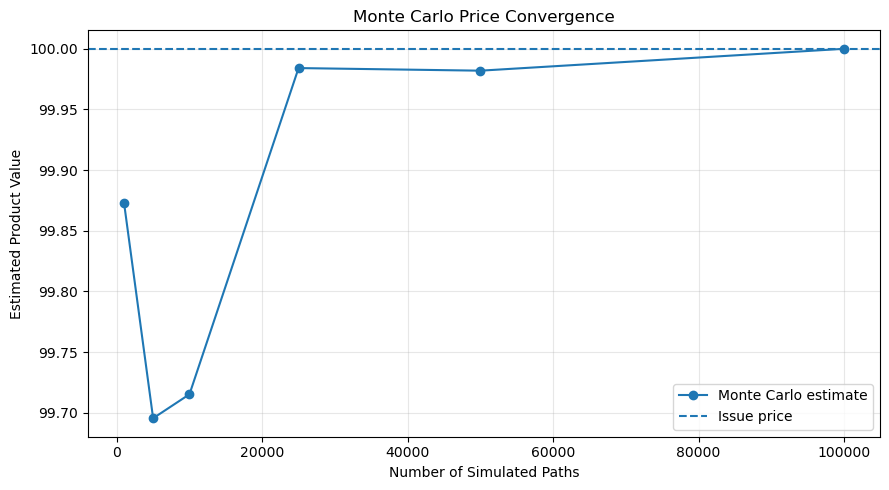

In [49]:
# Plot Monte Carlo price convergence

plt.figure(figsize=(9, 5))

plt.plot(
    sample_sizes,
    convergence_prices,
    marker="o",
    label="Monte Carlo estimate"
)

plt.axhline(
    y=issue_price,
    linestyle="--",
    label="Issue price"
)

plt.xlabel("Number of Simulated Paths")
plt.ylabel("Estimated Product Value")
plt.title("Monte Carlo Price Convergence")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Convergence Analysis

The Monte Carlo estimate becomes progressively more stable as the number of simulated paths increases.

With a relatively small simulation sample, the estimated product value can deviate from its calibrated target because of sampling variability. As the number of paths increases, the estimate stabilizes around the value obtained using the full simulation sample.

Using 100,000 simulated paths, the estimated standard error is approximately **0.0405**, corresponding to an approximate 95% confidence interval of **[99.9205, 100.0795]** around the calibrated Monte Carlo estimate.

The final estimate of exactly 100 should not be interpreted as perfect numerical precision. The fair coupon was calibrated using the same Monte Carlo sample, so the full-sample price equals the issue price by construction. The non-zero standard error highlights the remaining sampling uncertainty associated with the finite simulation.

Increasing the number of simulations would further reduce the Monte Carlo sampling error at the usual approximate rate of:

$$
SE \propto \frac{1}{\sqrt{M}}
$$

where $M$ is the number of simulated paths.

## Risk Analysis

After calibration, the coupon rate is fixed at its fair initial level.

The product is then repriced under instantaneous changes in the main market variables while the contractual terms, observation schedule and time to maturity are held fixed.

The analysis considers changes in:

- the underlying spot price;
- volatility;
- interest rates.

During the sensitivity analysis, the contractual barriers remain fixed at the levels determined at inception. Only the selected market variable is changed.

These scenarios therefore represent market shocks around the initial valuation date rather than the valuation of a seasoned note after time has elapsed.

In [21]:
def price_autocall_scenario(
    current_spot,
    current_rate,
    current_dividend,
    current_volatility,
    coupon_rate,
    random_seed=42
):
    """
    Reprice the autocallable note under a given market scenario.
    """

    # Simulate new risk-neutral paths from the current spot
    scenario_paths = simulate_paths(
        spot=current_spot,
        risk_free_rate=current_rate,
        dividend_yield=current_dividend,
        volatility=current_volatility,
        n_simulations=n_simulations,
        n_observations=n_observations,
        dt=dt,
        random_seed=random_seed
    )

    # Store the present value of each simulated path
    present_values = []

    # Calculate the payoff and present value for each path
    for path in scenario_paths:

        cash_flows = autocall_payoff(
            path,
            coupon_rate
        )

        path_present_value = 0.0

        for time, cash_flow in cash_flows:

            discount_factor = np.exp(
                -current_rate * time
            )

            path_present_value += (
                cash_flow * discount_factor
            )

        present_values.append(
            path_present_value
        )

    return np.mean(present_values)

### Spot Sensitivity

The underlying spot price is varied while all other market parameters and contractual terms are held constant.

The contractual barriers remain fixed at their inception levels. Therefore, changes in the current spot price modify the distance between the underlying and the coupon, autocall and protection barriers.

The fair coupon calibrated at inception is also kept fixed throughout the analysis.

In [22]:
# Define spot scenarios

spot_scenarios = np.arange(
    60.0,
    141.0,
    5.0
)

spot_prices = []

# Reprice the product for each spot scenario
for scenario_spot in spot_scenarios:

    scenario_price = price_autocall_scenario(
        current_spot=scenario_spot,
        current_rate=risk_free_rate,
        current_dividend=dividend_yield,
        current_volatility=volatility,
        coupon_rate=fair_coupon_rate,
        random_seed=random_seed
    )

    spot_prices.append(scenario_price)

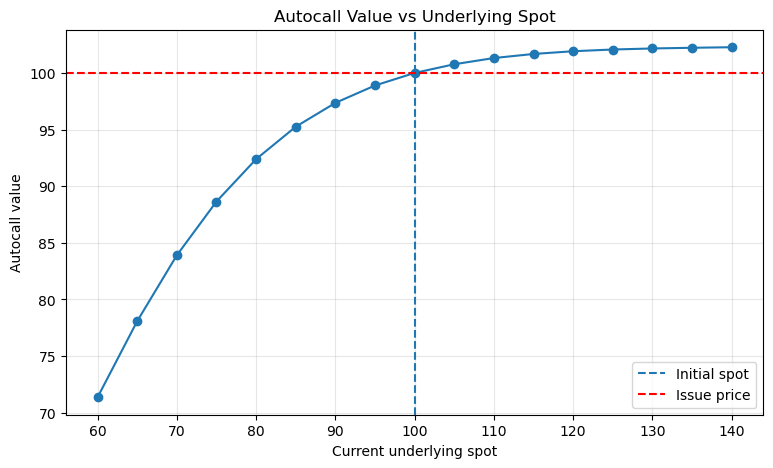

In [23]:
# Plot spot sensitivity

plt.figure(figsize=(9, 5))

plt.plot(
    spot_scenarios,
    spot_prices,
    marker="o"
)

plt.axvline(
    initial_spot,
    linestyle="--",
    label="Initial spot"
)

plt.axhline(
    issue_price,
    linestyle="--",
    label="Issue price",color="red"
)

plt.xlabel("Current underlying spot")
plt.ylabel("Autocall value")
plt.title("Autocall Value vs Underlying Spot")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

#### Interpretation

The value of the autocallable increases with the underlying spot price, but the relationship is strongly non-linear.

At low spot levels, an increase in the underlying significantly reduces the probability of capital loss at maturity and increases the probability of receiving conditional coupons. The product therefore exhibits relatively high spot sensitivity in this region.

As the underlying moves above its initial level, the value of the note gradually flattens. Higher spot levels increase the probability of early redemption, limiting the investor's participation in further upside movements.

The decreasing slope of the price curve illustrates the non-linear spot exposure created by the autocall feature. From a trading-desk perspective, this implies that the delta of the product changes materially as the underlying moves.

### Volatility Sensitivity

The volatility of the underlying is varied while the spot price, interest rate, dividend yield, contractual barriers and coupon rate are held constant.

This analysis measures how changes in uncertainty about future underlying prices affect the theoretical value of the autocallable note.

In [24]:
# Define volatility scenarios

volatility_scenarios = np.arange(
    0.10,
    0.41,
    0.025
)

volatility_prices = []

# Reprice the product for each volatility scenario
for scenario_volatility in volatility_scenarios:

    scenario_price = price_autocall_scenario(
        current_spot=initial_spot,
        current_rate=risk_free_rate,
        current_dividend=dividend_yield,
        current_volatility=scenario_volatility,
        coupon_rate=fair_coupon_rate,
        random_seed=random_seed
    )

    volatility_prices.append(scenario_price)

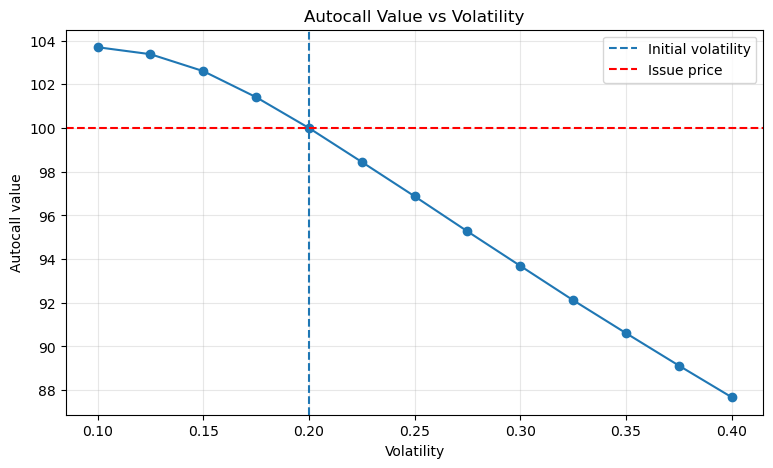

In [25]:
# Plot volatility sensitivity

plt.figure(figsize=(9, 5))

plt.plot(
    volatility_scenarios,
    volatility_prices,
    marker="o"
)

plt.axvline(
    volatility,
    linestyle="--",
    label="Initial volatility"
)

plt.axhline(
    issue_price,
    linestyle="--",
    label="Issue price",color="red"
)

plt.xlabel("Volatility")
plt.ylabel("Autocall value")
plt.title("Autocall Value vs Volatility")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

#### Interpretation

The value of the autocallable decreases as volatility increases, indicating negative vega under the model assumptions.

Higher volatility increases the dispersion of future underlying prices. While strong upward movements are partially capped by the autocall mechanism, large downward movements can increase the probability of missed coupons and capital losses below the protection barrier.

The payoff is therefore asymmetric: the investor has limited participation in large upward moves but remains exposed to significant downside scenarios.

As a result, higher volatility reduces the theoretical value of the note in this model.

### Interest Rate Sensitivity

The risk-free interest rate is varied while the underlying spot price, volatility, dividend yield, contractual barriers and coupon rate are held constant.

Changes in interest rates affect both the risk-neutral dynamics of the underlying and the present value of future product cash flows.

In [26]:
# Define interest-rate scenarios

rate_scenarios = np.arange(
    0.00,
    0.061,
    0.005
)

rate_prices = []

# Reprice the product for each interest-rate scenario
for scenario_rate in rate_scenarios:

    scenario_price = price_autocall_scenario(
        current_spot=initial_spot,
        current_rate=scenario_rate,
        current_dividend=dividend_yield,
        current_volatility=volatility,
        coupon_rate=fair_coupon_rate,
        random_seed=random_seed
    )

    rate_prices.append(scenario_price)

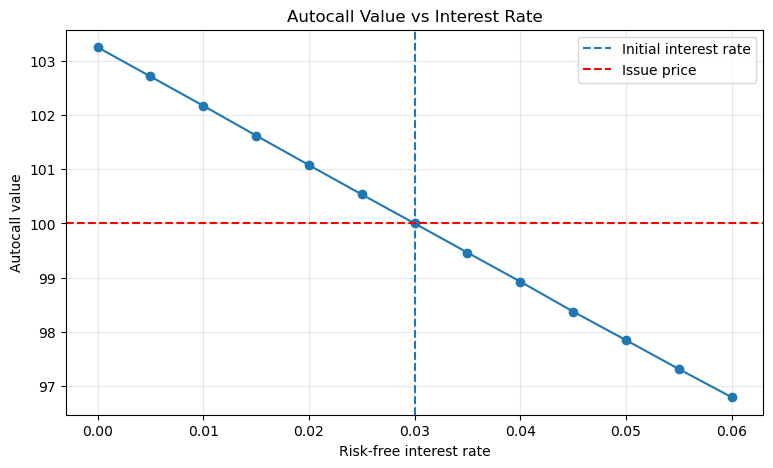

In [27]:
# Plot interest-rate sensitivity

plt.figure(figsize=(9, 5))

plt.plot(
    rate_scenarios,
    rate_prices,
    marker="o"
)

plt.axvline(
    risk_free_rate,
    linestyle="--",
    label="Initial interest rate"
)

plt.axhline(
    issue_price,
    linestyle="--",
    label="Issue price",color="red"
)

plt.xlabel("Risk-free interest rate")
plt.ylabel("Autocall value")
plt.title("Autocall Value vs Interest Rate")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

#### Interpretation

The value of the autocallable decreases as the risk-free interest rate increases, indicating negative rho under the model assumptions.

Higher interest rates have two main effects on the product. First, future coupon and redemption cash flows are discounted more heavily, reducing their present value.

Second, a higher risk-free rate increases the risk-neutral drift of the underlying through the term $r-q$, which affects the probability and timing of future coupon payments and early redemption.

Under the current product structure and model assumptions, the combined effect is a decrease in the theoretical value of the note as interest rates increase.

## Local Risk Measures

The local risk exposures of the autocallable note are estimated using finite differences around the initial market conditions.

The following sensitivities are considered:

$$
\Delta = \frac{\partial V}{\partial S}
$$

$$
\Gamma = \frac{\partial^2 V}{\partial S^2}
$$

$$
Vega = \frac{\partial V}{\partial \sigma}
$$

$$
\rho = \frac{\partial V}{\partial r}
$$

Because the product does not have a closed-form pricing formula, these sensitivities are approximated numerically by repricing the product after small changes in the relevant market variables.

The same random seed is used across bumped scenarios to reduce Monte Carlo noise.

In [28]:
# Spot bump used for finite differences

spot_bump = 1.0

# Reprice the product after upward and downward spot shocks

price_spot_up = price_autocall_scenario(
    current_spot=initial_spot + spot_bump,
    current_rate=risk_free_rate,
    current_dividend=dividend_yield,
    current_volatility=volatility,
    coupon_rate=fair_coupon_rate,
    random_seed=random_seed
)

price_spot_down = price_autocall_scenario(
    current_spot=initial_spot - spot_bump,
    current_rate=risk_free_rate,
    current_dividend=dividend_yield,
    current_volatility=volatility,
    coupon_rate=fair_coupon_rate,
    random_seed=random_seed
)

In [29]:
# Estimate delta using a central finite difference

delta = (
    price_spot_up
    - price_spot_down
) / (2 * spot_bump)

print(f"Delta: {delta:.4f}")

Delta: 0.1903


In [30]:
# Estimate gamma using a central finite difference

gamma = (
    price_spot_up
    - 2 * fair_price
    + price_spot_down
) / (spot_bump ** 2)

print(f"Gamma: {gamma:.4f}")

Gamma: -0.0217


In [31]:
# Volatility bump used for finite differences

volatility_bump = 0.01

# Reprice the product after upward and downward volatility shocks

price_vol_up = price_autocall_scenario(
    current_spot=initial_spot,
    current_rate=risk_free_rate,
    current_dividend=dividend_yield,
    current_volatility=volatility + volatility_bump,
    coupon_rate=fair_coupon_rate,
    random_seed=random_seed
)

price_vol_down = price_autocall_scenario(
    current_spot=initial_spot,
    current_rate=risk_free_rate,
    current_dividend=dividend_yield,
    current_volatility=volatility - volatility_bump,
    coupon_rate=fair_coupon_rate,
    random_seed=random_seed
)

# Estimate vega using a central finite difference

vega = (
    price_vol_up
    - price_vol_down
) / (2 * volatility_bump)

print(f"Vega: {vega:.4f}")

# Express vega per 1 percentage point increase in volatility

vega_1pct = vega * 0.01

print(f"Vega per 1 vol point: {vega_1pct:.4f}")

Vega: -60.4414
Vega per 1 vol point: -0.6044


In [32]:
# Interest-rate bump used for finite differences

rate_bump = 0.001

# Reprice the product after upward and downward interest-rate shocks

price_rate_up = price_autocall_scenario(
    current_spot=initial_spot,
    current_rate=risk_free_rate + rate_bump,
    current_dividend=dividend_yield,
    current_volatility=volatility,
    coupon_rate=fair_coupon_rate,
    random_seed=random_seed
)

price_rate_down = price_autocall_scenario(
    current_spot=initial_spot,
    current_rate=risk_free_rate - rate_bump,
    current_dividend=dividend_yield,
    current_volatility=volatility,
    coupon_rate=fair_coupon_rate,
    random_seed=random_seed
)

# Estimate rho using a central finite difference

rho = (
    price_rate_up
    - price_rate_down
) / (2 * rate_bump)

print(f"Rho: {rho:.4f}")

# Express rho per 1 basis point increase in interest rates

rho_1bp = rho * 0.0001

print(f"Rho per 1 bp: {rho_1bp:.4f}")

Rho: -100.7035
Rho per 1 bp: -0.0101


In [33]:
# Summarize the local risk measures

risk_metrics = pd.DataFrame({
    "Risk Measure": [
        "Delta",
        "Gamma",
        "Vega (per 1 vol point)",
        "Rho (per 1 bp)"
    ],
    "Value": [
        delta,
        gamma,
        vega_1pct,
        rho_1bp
    ]
})

risk_metrics

,Risk Measure,Value
0,Delta,0.190314
1,Gamma,-0.021667
2,Vega (per 1 vol point),-0.604414
3,Rho (per 1 bp),-0.010070


### Risk Interpretation

Around the initial market conditions, the investor position has a positive Delta and negative Gamma, Vega and Rho.

The positive Delta indicates that a small increase in the underlying level increases the value of the note. The negative Gamma reflects the local concavity of the payoff profile, as the investor's upside becomes increasingly limited by the possibility of early redemption.

The negative Vega indicates that, locally, an increase in implied volatility reduces the value of the investor position. Higher volatility increases the dispersion of future underlying outcomes, while the investor has limited upside through the autocall mechanism and remains exposed to significant downside scenarios below the protection barrier.

The negative Rho indicates that, under the model assumptions, an increase in interest rates reduces the value of the investor position. The interest-rate sensitivity captures both the effect of rates on risk-neutral underlying dynamics and the discounting of future cash flows.

These sensitivities are local and state-dependent. Their signs and magnitudes may change as the underlying level, volatility, interest rates, time to maturity and path history evolve.

From the issuer's perspective, the unhedged position is the opposite of the investor position. The issuer therefore has approximately the opposite Delta, Gamma, Vega and Rho exposures before hedging.

## Product Outcome Analysis

Beyond the theoretical value and local risk measures, the Monte Carlo simulation can be used to analyse the possible outcomes of the autocallable note.

The analysis focuses on:

- the probability of early redemption;
- the distribution of autocall dates;
- the probability of reaching maturity without being autocalled;
- the probability of capital loss at maturity.

These metrics provide an intuitive view of the product from the investor's perspective and complement the pricing and risk analysis.

In [34]:
def get_autocall_time(path):
    """
    Return the autocall time for one underlying path.

    If the product is never autocalled, return None.
    """

    # Loop through all observation dates
    for i, time in enumerate(observation_times):

        # Extract the underlying level at this observation date
        current_spot = path[i + 1]

        # Check whether the autocall is active
        # and whether the underlying is above the autocall barrier
        if (
            time >= non_call_period
            and time < maturity
            and current_spot >= autocall_barrier_level
        ):

            return time

    # No autocall occurred during the life of the product
    return None

In [35]:
# Determine the autocall time for each simulated path

autocall_results = [
    get_autocall_time(path)
    for path in simulated_paths
]

In [36]:
# Calculate the overall autocall probability

autocall_probability = np.mean([
    time is not None
    for time in autocall_results
])

maturity_probability = 1 - autocall_probability

print(f"Autocall probability: {autocall_probability:.2%}")
print(f"Probability of reaching maturity: {maturity_probability:.2%}")

Autocall probability: 70.73%
Probability of reaching maturity: 29.27%


In [37]:
# Keep only paths that were autocalled

autocall_times_observed = [
    time
    for time in autocall_results
    if time is not None
]

# Count the number of autocalls at each observation date

autocall_distribution = (
    pd.Series(autocall_times_observed)
    .value_counts()
    .sort_index()
)

autocall_distribution

1.00    48123
1.25     7286
1.50     4519
1.75     3224
2.00     2538
2.25     1999
2.50     1668
2.75     1372
Name: count, dtype: int64

In [38]:
# Express autocall frequencies as probabilities
# across all simulated paths

autocall_probabilities = (
    autocall_distribution
    / n_simulations
)

autocall_probabilities

1.00    0.48123
1.25    0.07286
1.50    0.04519
1.75    0.03224
2.00    0.02538
2.25    0.01999
2.50    0.01668
2.75    0.01372
Name: count, dtype: float64

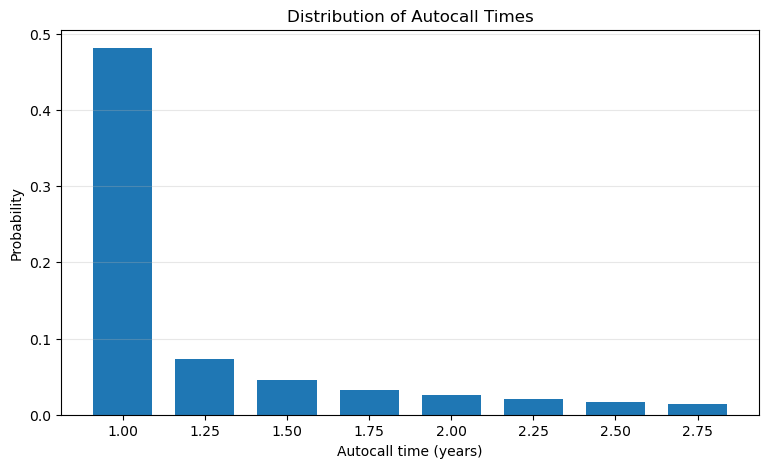

In [39]:
plt.figure(figsize=(9, 5))

plt.bar(
    autocall_probabilities.index,
    autocall_probabilities.values,
    width=0.18
)

plt.xlabel("Autocall time (years)")
plt.ylabel("Probability")
plt.title("Distribution of Autocall Times")
plt.grid(axis="y", alpha=0.3)

plt.show()

#### Interpretation

The distribution of autocall times is strongly concentrated at the first eligible observation date.

A large proportion of simulated paths are autocalled after one year, when the non-call period ends. At subsequent observation dates, the probability of a first autocall progressively decreases because paths that previously satisfied the autocall condition have already terminated.

Overall, approximately **70.7%** of simulated paths are redeemed early, while **29.3%** reach the final contractual maturity without being autocalled.

These probabilities are generated under the risk-neutral measure used for pricing and should therefore be interpreted as model-implied probabilities rather than forecasts of real-world frequencies.

This illustrates an important feature of autocallable products: although the contractual maximum maturity is three years, the effective lifetime of the note can be significantly shorter because of the early-redemption mechanism.

In [40]:
# Identify paths that reach maturity without being autocalled

maturity_paths = [
    path
    for path, autocall_time in zip(
        simulated_paths,
        autocall_results
    )
    if autocall_time is None
]

# Identify maturity paths ending below the protection barrier

capital_loss_paths = [
    path
    for path in maturity_paths
    if path[-1] < protection_barrier_level
]

# Probability of capital loss across all simulated paths

capital_loss_probability = (
    len(capital_loss_paths)
    / n_simulations
)

# Probability of capital loss conditional on reaching maturity

conditional_loss_probability = (
    len(capital_loss_paths)
    / len(maturity_paths)
)

print(
    f"Probability of capital loss: "
    f"{capital_loss_probability:.2%}"
)

print(
    f"Probability of capital loss given maturity: "
    f"{conditional_loss_probability:.2%}"
)

Probability of capital loss: 7.16%
Probability of capital loss given maturity: 24.45%


### Downside Risk

Approximately **7.2%** of all simulated paths result in a capital loss at maturity.

Conditional on the product reaching its final maturity without being autocalled, the probability of capital loss increases to approximately **24.5%**.

This difference reflects the path-dependent nature of the autocallable note. Stronger underlying paths are more likely to terminate early through the autocall mechanism, while paths that survive until maturity are more concentrated in weaker underlying scenarios.

The downside protection barrier therefore reduces the frequency of capital losses but does not eliminate downside exposure. If the underlying finishes below the protection barrier, the investor participates directly in the negative performance of the underlying.

These probabilities are calculated under the risk-neutral pricing measure and should not be interpreted as estimates of real-world loss frequencies.

In [41]:
# Calculate capital losses in scenarios ending below the protection barrier

capital_losses = np.array([
    notional
    - notional * path[-1] / initial_spot
    for path in capital_loss_paths
])

# Calculate summary statistics

average_capital_loss = np.mean(capital_losses)
median_capital_loss = np.median(capital_losses)
worst_capital_loss = np.max(capital_losses)

print(
    f"Average capital loss given loss: "
    f"{average_capital_loss:.2f}"
)

print(
    f"Median capital loss given loss: "
    f"{median_capital_loss:.2f}"
)

print(
    f"Worst simulated capital loss: "
    f"{worst_capital_loss:.2f}"
)

Average capital loss given loss: 48.58
Median capital loss given loss: 47.24
Worst simulated capital loss: 77.53


#### Loss Severity

Conditional on a principal loss occurring at maturity, the average simulated principal loss is approximately **48.6% of notional**, while the median principal loss is approximately **47.2%**.

The worst principal loss observed across the Monte Carlo simulation is approximately **77.5% of notional**.

These figures measure the reduction in principal redemption at maturity and do not represent the investor's total economic P&L, since coupons may have been received earlier in the life of the product.

The results highlight the asymmetric risk profile of the autocallable note. The protection barrier reduces the frequency of principal losses, but once the final underlying level falls below the barrier, the investor becomes directly exposed to the downside performance of the underlying.

The worst simulated principal loss should not be interpreted as the theoretical maximum loss. It only represents the most severe outcome observed within the simulated sample. In principle, if the underlying were to fall close to zero, the investor could lose almost the entire notional.

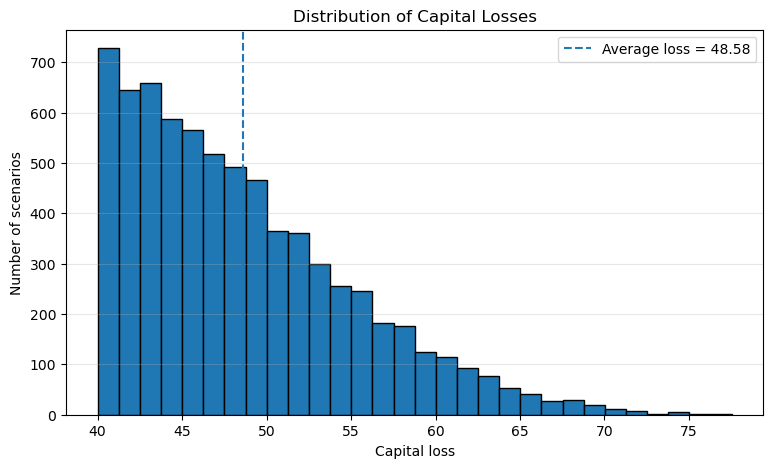

In [42]:
# Plot the distribution of capital losses

plt.figure(figsize=(9, 5))

plt.hist(
    capital_losses,
    bins=30,
    edgecolor="black"
)

plt.axvline(
    average_capital_loss,
    linestyle="--",
    label=f"Average loss = {average_capital_loss:.2f}"
)

plt.xlabel("Capital loss")
plt.ylabel("Number of scenarios")
plt.title("Distribution of Capital Losses")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

## Product Summary

The table below summarizes the main structural characteristics, pricing results, model-implied outcome probabilities and local risk measures of the autocallable note under the initial market assumptions.

In [52]:
# Create a summary of the main product and risk metrics

product_summary = pd.DataFrame({
    "Metric": [
        "Issue Price",
        "Maximum Maturity",
        "Fair Quarterly Coupon",
        "Indicative Annual Coupon",
        "Autocall Probability",
        "Probability of Reaching Maturity",
        "Probability of Principal Loss",
        "Probability of Principal Loss Given Maturity",
        "Average Principal Loss Given Loss",
        "Delta",
        "Gamma",
        "Vega per 1 Vol Point",
        "Rho per 1 bp"
    ],

    "Value": [
        f"{issue_price:.2f}",
        f"{maturity:.1f} years",
        f"{fair_coupon_rate:.2%}",
        f"{4 * fair_coupon_rate:.2%}",
        f"{autocall_probability:.2%}",
        f"{maturity_probability:.2%}",
        f"{capital_loss_probability:.2%}",
        f"{conditional_loss_probability:.2%}",
        f"{average_capital_loss:.2f}",
        f"{delta:.4f}",
        f"{gamma:.4f}",
        f"{vega_1pct:.4f}",
        f"{rho_1bp:.4f}"
    ]
})

product_summary

,Metric,Value
0,Issue Price,100.00
1,Maximum Maturity,3.0 years
2,Fair Quarterly Coupon,1.34%
3,Indicative Annual Coupon,5.37%
4,Autocall Probability,70.73%
5,Probability of Reaching Maturity,29.27%
6,Probability of Principal Loss,7.16%
7,Probability of Principal Loss Given Maturity,24.45%
8,Average Principal Loss Given Loss,48.58
9,Delta,0.1903


### Economic Interpretation

Under the initial market assumptions, the model calibrates a fair quarterly coupon of approximately **1.34%**, corresponding to an indicative simple annual coupon of approximately **5.37%**.

The note has a maximum maturity of three years, although approximately **70.7%** of simulated paths terminate early through the autocall mechanism. Approximately **29.3%** of paths reach final maturity.

Capital losses occur in approximately **7.2%** of all simulated paths. However, conditional on the product surviving until maturity, approximately **24.5%** of paths result in a capital loss. When a capital loss occurs, its average simulated magnitude is approximately **48.6% of notional**.

Around the initial market conditions, the investor position exhibits positive delta, negative gamma, negative vega and negative rho. These exposures reflect the asymmetric payoff of the product: upside participation is limited by early redemption, while significant downside exposure remains possible below the protection barrier.

The outcome probabilities and valuation results are model-dependent and are generated under the risk-neutral measure. They should therefore be interpreted as pricing-model outputs rather than forecasts of real-world investment outcomes.

## Model Limitations and Extensions

The pricing framework developed in this project is intentionally simplified in order to focus on the main economic mechanisms of the autocallable note.

### Constant Volatility

The underlying is modelled using a geometric Brownian motion with constant volatility.

In practice, equity derivatives markets exhibit both volatility skew and term structure, meaning that implied volatility depends on strike and maturity. This is particularly relevant for autocallable products because their value is sensitive to downside scenarios around the coupon and protection barriers.

A more advanced implementation could therefore use a local volatility or stochastic volatility model calibrated to the market implied volatility surface.

### Constant Interest Rate

The model assumes a single constant risk-free interest rate over the entire life of the product.

In practice, discounting and forward dynamics would be derived from the relevant interest-rate term structure rather than from a single constant rate.

### Constant Dividend Yield

The underlying is assumed to pay a constant continuous dividend yield.

For an equity index, a trading desk would typically use a dividend term structure or market-implied forward levels. For single stocks, expected discrete dividends may also need to be modelled explicitly.

### Issuer Credit and Funding

The framework assumes risk-free discounting and does not explicitly incorporate issuer credit risk or funding costs.

In practice, structured-note valuation may depend on the issuer's funding level and credit spread, which can affect both the economic value of the note and the coupon offered to investors.

### Transaction Costs and Dynamic Hedging

The model calculates theoretical risk sensitivities but does not simulate the dynamic hedging strategy of the issuing desk.

Real-world hedging would involve transaction costs, discrete rebalancing, liquidity constraints and potentially significant changes in Greeks as the underlying approaches coupon, autocall or protection barriers.

### Model Risk

The calibrated fair coupon and risk measures are model-dependent. A more sophisticated model incorporating the market volatility surface, interest-rate and dividend curves, issuer funding and more realistic underlying dynamics could produce different valuations and sensitivities.
### Model Extensions

Possible extensions include:

- calibration to a market implied volatility surface;
- local volatility or stochastic volatility dynamics;
- a full interest-rate and dividend term structure;
- issuer credit and funding adjustments;
- dynamic hedging simulations;
- multi-asset worst-of autocallable structures;
- Monte Carlo variance-reduction techniques.

## Conclusion

This project developed a framework for structuring, pricing and analysing a single-underlying autocallable note with conditional memory coupons and downside protection.

The contractual payoff was first implemented and validated before introducing a risk-neutral Monte Carlo pricing framework. Rather than assuming an arbitrary coupon, the fair coupon was calibrated so that the theoretical value of the note matched its issue price.

The product was then repriced under instantaneous changes in spot, volatility and interest rates, and local Delta, Gamma, Vega and Rho exposures were estimated using finite differences.

Finally, the Monte Carlo simulations were used to analyse the model-implied economic behaviour of the note, including early-redemption probabilities, maturity outcomes and downside-loss severity.

The framework illustrates how the interaction between conditional coupons, automatic early redemption and downside protection creates the non-linear and path-dependent risk profile characteristic of autocallable structured products.

The results remain dependent on the modelling assumptions and should be interpreted within the risk-neutral pricing framework rather than as forecasts of real-world investment outcomes.